# E-Commerce Sales & Business Performance Analysis

## CodeAlpha Data Analytics Internship  
**Task:** Task 2 – Data Visualization

**Notebook By:** Ranjana Singh

**Dataset:** Brazilian E-Commerce Public Dataset by Olist

**Source:** Kaggle

**Tools:** Python, Pandas, Matplotlib, Seaborn and Tableau

---

## Introduction

This project analyses real-world e-commerce data to explore sales performance, customer behaviour, product trends and business operations.

## 1. Loading and Exploring the Dataset

In [1]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/rrrranjana/olist-e-commerce-data/archive/olist_customers_dataset.csv
/kaggle/input/datasets/rrrranjana/olist-e-commerce-data/archive/olist_geolocation_dataset.csv
/kaggle/input/datasets/rrrranjana/olist-e-commerce-data/archive/olist_order_items_dataset.csv
/kaggle/input/datasets/rrrranjana/olist-e-commerce-data/archive/olist_order_payments_dataset.csv
/kaggle/input/datasets/rrrranjana/olist-e-commerce-data/archive/olist_order_reviews_dataset.csv
/kaggle/input/datasets/rrrranjana/olist-e-commerce-data/archive/olist_orders_dataset.csv
/kaggle/input/datasets/rrrranjana/olist-e-commerce-data/archive/olist_products_dataset.csv
/kaggle/input/datasets/rrrranjana/olist-e-commerce-data/archive/olist_sellers_dataset.csv
/kaggle/input/datasets/rrrranjana/olist-e-commerce-data/archive/product_category_name_translation.csv


## 2. Importing Libraries

- **Pandas:** Loading and analysing business data.
- **NumPy:** Performing numerical calculations.
- **Matplotlib:** Creating data visualizations.
- **Seaborn:** Creating statistical charts.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


## 3. Loading the E-Commerce Datasets

The Olist dataset contains nine CSV files, each representing a different part of the e-commerce business, such as orders, customers, products, sellers, payments and reviews.

Each file is loaded into a separate Pandas DataFrame for further analysis.

In [3]:
import os

for dirname, _, filenames in os.walk("/kaggle/input"):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/rrrranjana/olist-e-commerce-data/archive/olist_customers_dataset.csv
/kaggle/input/datasets/rrrranjana/olist-e-commerce-data/archive/olist_geolocation_dataset.csv
/kaggle/input/datasets/rrrranjana/olist-e-commerce-data/archive/olist_order_items_dataset.csv
/kaggle/input/datasets/rrrranjana/olist-e-commerce-data/archive/olist_order_payments_dataset.csv
/kaggle/input/datasets/rrrranjana/olist-e-commerce-data/archive/olist_order_reviews_dataset.csv
/kaggle/input/datasets/rrrranjana/olist-e-commerce-data/archive/olist_orders_dataset.csv
/kaggle/input/datasets/rrrranjana/olist-e-commerce-data/archive/olist_products_dataset.csv
/kaggle/input/datasets/rrrranjana/olist-e-commerce-data/archive/olist_sellers_dataset.csv
/kaggle/input/datasets/rrrranjana/olist-e-commerce-data/archive/product_category_name_translation.csv


## 4. Loading Data into Pandas DataFrames

Each CSV file is loaded into a separate DataFrame to organise the e-commerce data for further analysis.

In [4]:
import os
import pandas as pd

file_paths = {}

for dirname, _, filenames in os.walk("/kaggle/input"):
    for filename in filenames:
        if filename.endswith(".csv"):
            file_paths[filename] = os.path.join(dirname, filename)

customers = pd.read_csv(file_paths["olist_customers_dataset.csv"])
geolocation = pd.read_csv(file_paths["olist_geolocation_dataset.csv"])
order_items = pd.read_csv(file_paths["olist_order_items_dataset.csv"])
payments = pd.read_csv(file_paths["olist_order_payments_dataset.csv"])
reviews = pd.read_csv(file_paths["olist_order_reviews_dataset.csv"])
orders = pd.read_csv(file_paths["olist_orders_dataset.csv"])
products = pd.read_csv(file_paths["olist_products_dataset.csv"])
sellers = pd.read_csv(file_paths["olist_sellers_dataset.csv"])
category_translation = pd.read_csv(file_paths["product_category_name_translation.csv"])

print("All 9 datasets loaded successfully!")

All 9 datasets loaded successfully!


## 5. Understanding the Dataset Structure

In this step, we examine the number of rows and columns in each dataset to understand the size and structure of the e-commerce database.

In [5]:
datasets = {
    "Customers": customers,
    "Geolocation": geolocation,
    "Order Items": order_items,
    "Payments": payments,
    "Reviews": reviews,
    "Orders": orders,
    "Products": products,
    "Sellers": sellers,
    "Category Translation": category_translation
}

for name, data in datasets.items():
    print(f"{name}: {data.shape[0]} rows and {data.shape[1]} columns")

Customers: 99441 rows and 5 columns
Geolocation: 1000163 rows and 5 columns
Order Items: 112650 rows and 7 columns
Payments: 103886 rows and 5 columns
Reviews: 99224 rows and 7 columns
Orders: 99441 rows and 8 columns
Products: 32951 rows and 9 columns
Sellers: 3095 rows and 4 columns
Category Translation: 71 rows and 2 columns


## 6. Examining Columns and Data Types

This step examines the column names and data types of each dataset to understand the available business information and identify fields that may require data cleaning.

In [6]:
for name, data in datasets.items():
    print(f"\n--- {name} ---")
    print("Columns:", list(data.columns))
    print("\nData Types:")
    print(data.dtypes)


--- Customers ---
Columns: ['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

Data Types:
customer_id                 object
customer_unique_id          object
customer_zip_code_prefix     int64
customer_city               object
customer_state              object
dtype: object

--- Geolocation ---
Columns: ['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng', 'geolocation_city', 'geolocation_state']

Data Types:
geolocation_zip_code_prefix      int64
geolocation_lat                float64
geolocation_lng                float64
geolocation_city                object
geolocation_state               object
dtype: object

--- Order Items ---
Columns: ['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

Data Types:
order_id                object
order_item_id            int64
product_id              object
seller_id               object
shipping_limit_date     object
pr

## 7. Data Quality Assessment

In this step, we check for missing values and duplicate records across all nine datasets to identify potential data quality issues before performing business analysis.

In [7]:
for name, data in datasets.items():
    print(f"\n--- {name} ---")

    print("Missing values:", data.isnull().sum().sum())
    print("Duplicate rows:", data.duplicated().sum())


--- Customers ---
Missing values: 0
Duplicate rows: 0

--- Geolocation ---
Missing values: 0
Duplicate rows: 261831

--- Order Items ---
Missing values: 0
Duplicate rows: 0

--- Payments ---
Missing values: 0
Duplicate rows: 0

--- Reviews ---
Missing values: 145903
Duplicate rows: 0

--- Orders ---
Missing values: 4908
Duplicate rows: 0

--- Products ---
Missing values: 2448
Duplicate rows: 0

--- Sellers ---
Missing values: 0
Duplicate rows: 0

--- Category Translation ---
Missing values: 0
Duplicate rows: 0


## 8. Statistical Summary of E-Commerce Data

This step uses descriptive statistics to understand numerical business data, including prices, freight charges, payments and product dimensions.

In [8]:
numerical_datasets = {
    "Order Items": order_items,
    "Payments": payments,
    "Products": products,
    "Reviews": reviews
}

for name, data in numerical_datasets.items():
    print(f"\n--- {name} ---")
    print(data.describe())


--- Order Items ---
       order_item_id          price  freight_value
count  112650.000000  112650.000000  112650.000000
mean        1.197834     120.653739      19.990320
std         0.705124     183.633928      15.806405
min         1.000000       0.850000       0.000000
25%         1.000000      39.900000      13.080000
50%         1.000000      74.990000      16.260000
75%         1.000000     134.900000      21.150000
max        21.000000    6735.000000     409.680000

--- Payments ---
       payment_sequential  payment_installments  payment_value
count       103886.000000         103886.000000  103886.000000
mean             1.092679              2.853349     154.100380
std              0.706584              2.687051     217.494064
min              1.000000              0.000000       0.000000
25%              1.000000              1.000000      56.790000
50%              1.000000              1.000000     100.000000
75%              1.000000              4.000000     171.83750

## 9. Order Status Analysis

This analysis examines the distribution of order statuses to understand how many orders were delivered, cancelled, unavailable or still in progress.

In [9]:
order_status = orders['order_status'].value_counts()

print("Order Status Distribution:")
print(order_status)

Order Status Distribution:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


## 10. Visualizing Order Status Distribution

A bar chart is used to compare the number of orders across different order statuses and understand the overall order fulfilment situation.

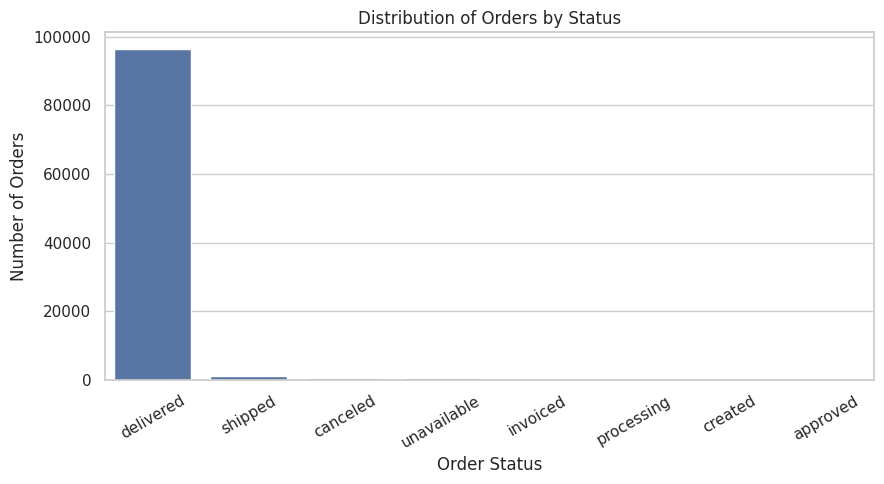

In [10]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=orders,
    x='order_status',
    order=orders['order_status'].value_counts().index
)

plt.title("Distribution of Orders by Status")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 11. Monthly Order Trend Analysis

This analysis examines the number of orders placed each month to identify seasonal patterns and changes in customer demand over time.

In [11]:
# Convert order purchase date into datetime format
orders['order_purchase_timestamp'] = pd.to_datetime(
    orders['order_purchase_timestamp']
)

# Extract month and year
orders['order_month'] = orders['order_purchase_timestamp'].dt.to_period('M')

# Count orders per month
monthly_orders = orders.groupby('order_month').size()

print(monthly_orders)

order_month
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M, dtype: int64


## 12. Monthly Order Trend Visualization

A line chart is used to visualize monthly order volumes and identify changes in customer demand over time.

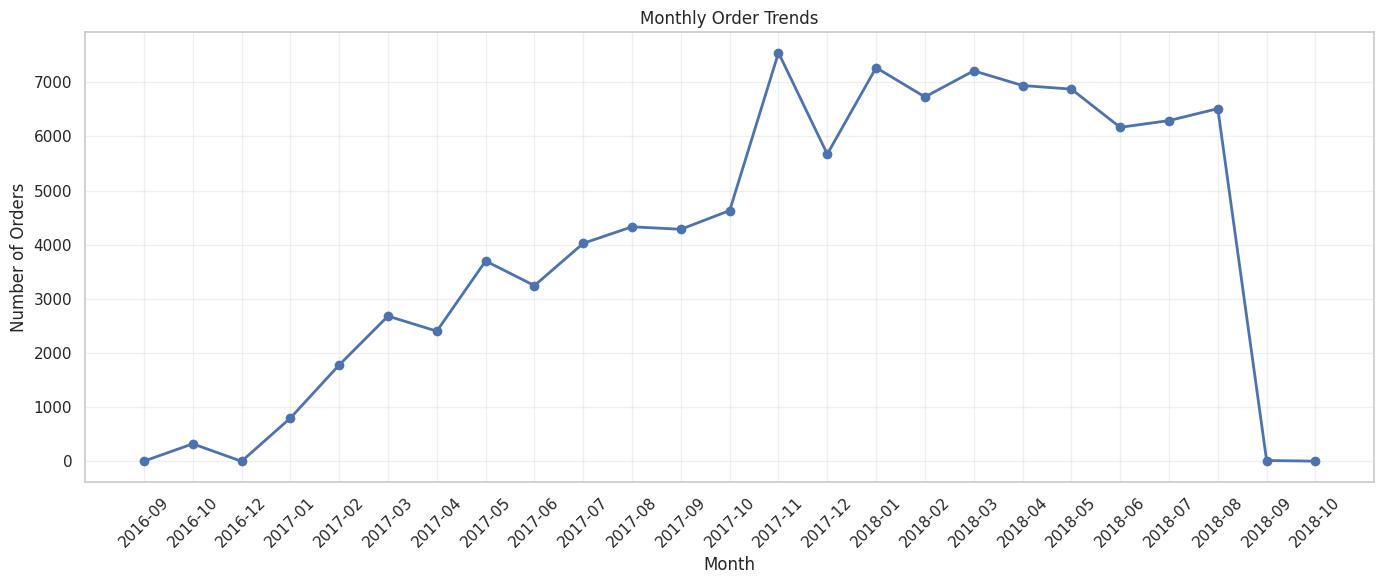

In [12]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_orders.index.astype(str),
    monthly_orders.values,
    marker='o',
    linewidth=2
)

plt.title("Monthly Order Trends")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 13. Revenue Analysis

This section analyses the total product sales generated from delivered orders. It helps evaluate the business's sales performance by focusing on successfully delivered orders.

In [13]:
# Merge order items with order details
sales_data = order_items.merge(
    orders[['order_id', 'order_status', 'order_purchase_timestamp']],
    on='order_id',
    how='left'
)

# Consider only delivered orders
delivered_sales = sales_data[
    sales_data['order_status'] == 'delivered'
].copy()

# Calculate total product sales
total_revenue = delivered_sales['price'].sum()

print("Total Revenue from Delivered Orders: ₹", round(total_revenue, 2))
print("Total Delivered Orders:", delivered_sales['order_id'].nunique())

Total Revenue from Delivered Orders: ₹ 13221498.11
Total Delivered Orders: 96478


## 14. Monthly Revenue Trend Analysis

This section examines monthly product sales from delivered orders. The visualization helps identify high-performing and low-performing months and understand the business's sales trends over time.

In [14]:
# Convert purchase date into datetime format
delivered_sales['order_purchase_timestamp'] = pd.to_datetime(
    delivered_sales['order_purchase_timestamp']
)

# Extract month from purchase date
delivered_sales['order_month'] = (
    delivered_sales['order_purchase_timestamp'].dt.to_period('M')
)

# Calculate monthly revenue
monthly_revenue = delivered_sales.groupby(
    'order_month'
)['price'].sum()

print(monthly_revenue)

order_month
2016-09       134.97
2016-10     40325.11
2016-12        10.90
2017-01    111798.36
2017-02    234223.40
2017-03    359198.85
2017-04    340669.68
2017-05    489338.25
2017-06    421923.37
2017-07    481604.52
2017-08    554699.70
2017-09    607399.67
2017-10    648247.65
2017-11    987765.37
2017-12    726033.19
2018-01    924645.00
2018-02    826437.13
2018-03    953356.25
2018-04    973534.09
2018-05    977544.69
2018-06    856077.86
2018-07    867953.46
2018-08    838576.64
Freq: M, Name: price, dtype: float64


## 15. Visualizing Monthly Revenue Trends

This line chart shows the changes in monthly product sales over time and helps identify sales patterns and trends.

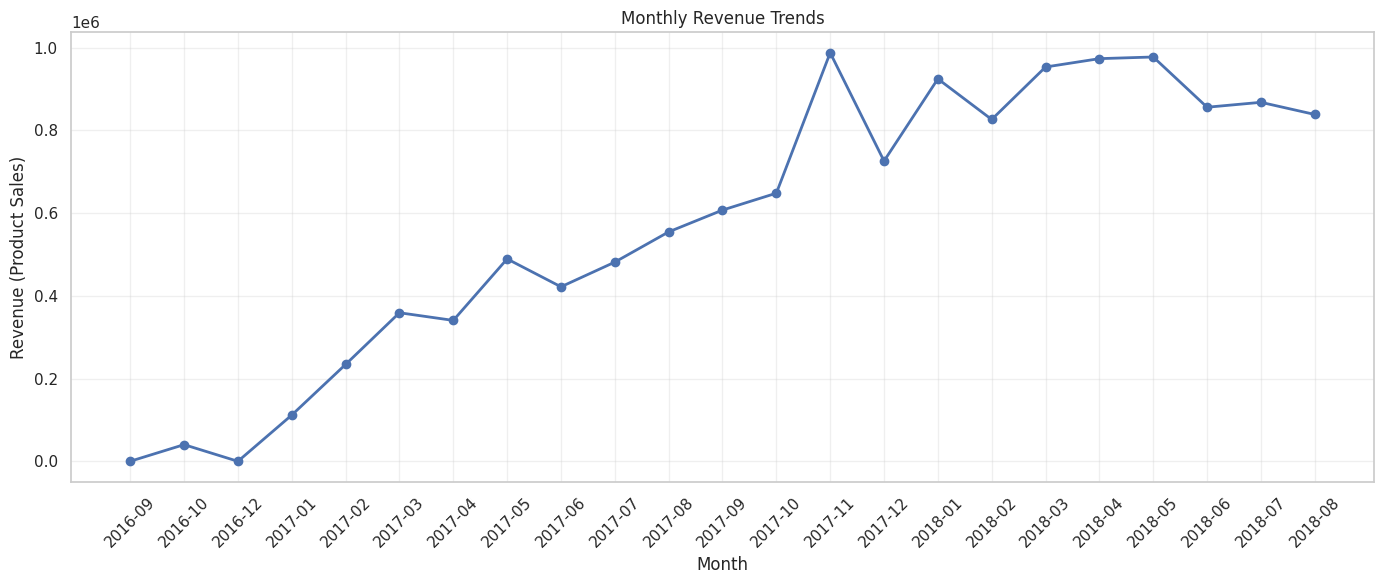

In [15]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_revenue.index.astype(str),
    monthly_revenue.values,
    marker='o',
    linewidth=2
)

plt.title("Monthly Revenue Trends")
plt.xlabel("Month")
plt.ylabel("Revenue (Product Sales)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 16. Product Category Analysis

This section analyses product categories to understand which types of products generate sales. It helps identify popular categories and understand product demand.

In [16]:
# Merge delivered sales with product details
category_data = delivered_sales.merge(
    products[['product_id', 'product_category_name']],
    on='product_id',
    how='left'
)

# Add English category names
category_data = category_data.merge(
    category_translation,
    on='product_category_name',
    how='left'
)

category_data['product_category_name_english'] = (
    category_data['product_category_name_english']
    .fillna('Unclassified')
)

category_sales = category_data.groupby(
    'product_category_name_english'
).agg(
    Total_Revenue=('price', 'sum'),
    Items_Sold=('product_id', 'count')
).sort_values('Total_Revenue', ascending=False)

print(category_sales.head(10))

                               Total_Revenue  Items_Sold
product_category_name_english                           
health_beauty                     1233131.72        9465
watches_gifts                     1166176.98        5859
bed_bath_table                    1023434.76       10953
sports_leisure                     954852.55        8431
computers_accessories              888724.61        7644
furniture_decor                    711927.69        8160
housewares                         615628.69        6795
cool_stuff                         610204.10        3718
auto                               578966.65        4140
toys                               471286.48        4030


## 17. Top-Selling Product Categories

This section identifies the top 10 product categories based on revenue. A bar chart is used to compare their sales performance.

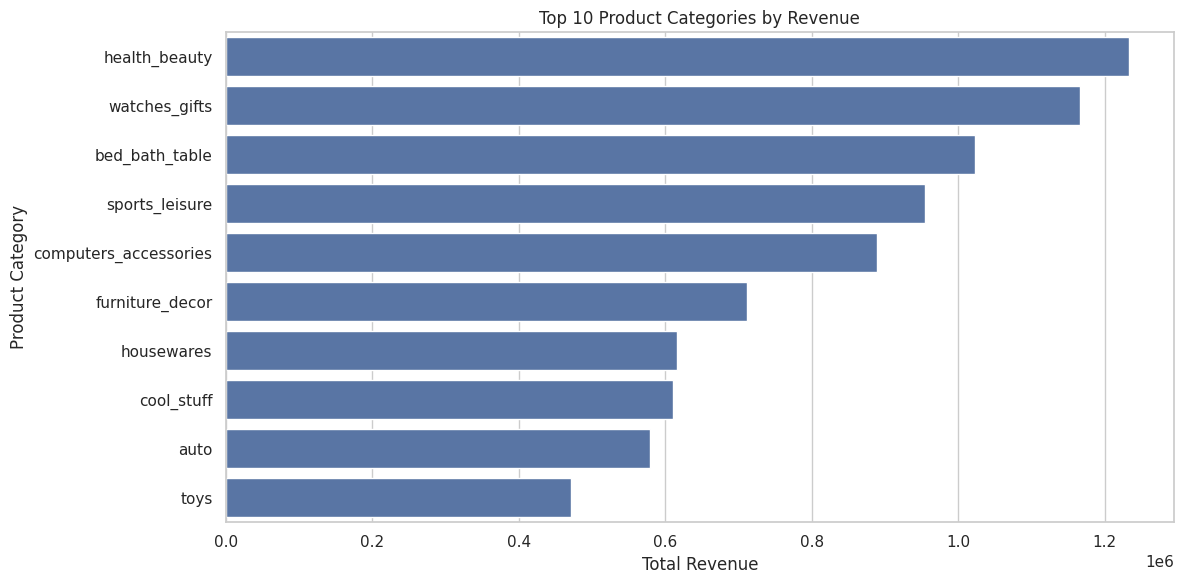

In [17]:
top_categories = category_sales.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_categories['Total_Revenue'],
    y=top_categories.index
)

plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

## 18. Customer Analysis

This section examines customer activity by analysing the total number of unique customers and identifying repeat customers. It helps understand customer purchasing behaviour.

In [18]:
customer_orders = orders[
    orders['order_status'] == 'delivered'
].merge(
    customers[['customer_id', 'customer_unique_id']],
    on='customer_id',
    how='left'
)

customer_purchase_counts = customer_orders.groupby(
    'customer_unique_id'
)['order_id'].nunique()

total_customers = customer_purchase_counts.size

repeat_customers = (
    customer_purchase_counts > 1
).sum()

print("Total Unique Customers:", total_customers)
print("Repeat Customers:", repeat_customers)
print(
    "One-Time Customers:",
    total_customers - repeat_customers
)

Total Unique Customers: 93358
Repeat Customers: 2801
One-Time Customers: 90557


## 19. Payment Method Analysis

This section analyses the different payment methods used by customers. It helps understand customer payment preferences and the distribution of transactions.

              Total_Payments  Total_Amount
payment_type                              
credit_card            76795   12542084.19
boleto                 19784    2869361.27
voucher                 5775     379436.87
debit_card              1529     217989.79
not_defined                3          0.00


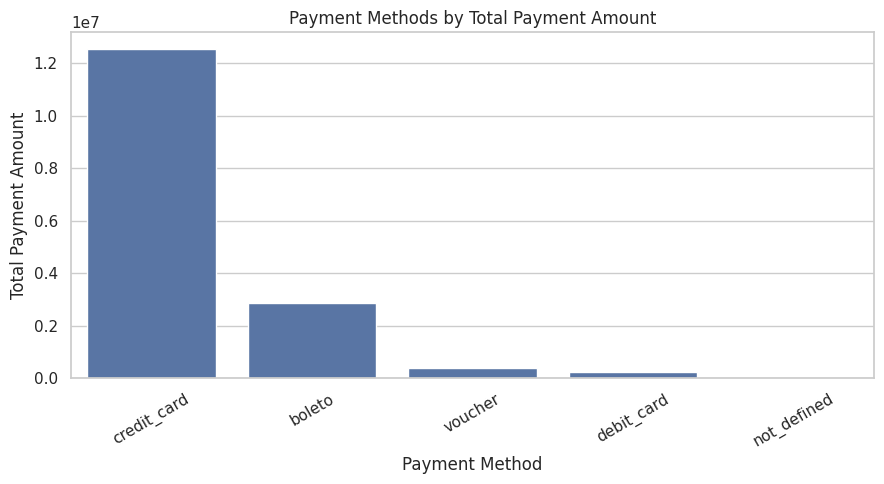

In [19]:
payment_summary = payments.groupby(
    'payment_type'
).agg(
    Total_Payments=('payment_value', 'count'),
    Total_Amount=('payment_value', 'sum')
).sort_values('Total_Amount', ascending=False)

print(payment_summary)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=payment_summary.index,
    y=payment_summary['Total_Amount']
)

plt.title("Payment Methods by Total Payment Amount")
plt.xlabel("Payment Method")
plt.ylabel("Total Payment Amount")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 20. Seller Performance Analysis

This section evaluates seller performance by examining the total product sales and number of orders associated with each seller. It helps identify high-performing sellers.

In [20]:
seller_data = delivered_sales.groupby(
    'seller_id'
).agg(
    Total_Revenue=('price', 'sum'),
    Total_Orders=('order_id', 'nunique')
).sort_values('Total_Revenue', ascending=False)

print("Top 10 Sellers by Revenue:")
print(seller_data.head(10))

Top 10 Sellers by Revenue:
                                  Total_Revenue  Total_Orders
seller_id                                                    
4869f7a5dfa277a7dca6462dcf3b52b2      226987.93          1124
53243585a1d6dc2643021fd1853d8905      217940.44           348
4a3ca9315b744ce9f8e9374361493884      196882.12          1772
fa1c13f2614d7b5c4749cbc52fecda94      190917.14           578
7c67e1448b00f6e969d365cea6b010ab      186570.05           973
7e93a43ef30c4f03f38b393420bc753a      165981.49           319
da8622b14eb17ae2831f4ac5b9dab84a      159816.87          1311
7a67c85e85bb2ce8582c35f2203ad736      139658.69          1145
1025f0e2d44d7041d6cf58b6550e0bfa      138208.56           910
955fee9216a65b617aa5c0531780ce60      131836.71          1261


## 21. Key Business Insights

This section summarises the important findings from the analysis, including revenue trends, popular product categories, customer behaviour and payment preferences.

In [21]:
print("========== KEY BUSINESS INSIGHTS ==========")

print("\n1. Total Revenue:")
print(round(total_revenue, 2))

print("\n2. Total Delivered Orders:")
print(delivered_sales['order_id'].nunique())

print("\n3. Best Month by Revenue:")
print(monthly_revenue.idxmax())

print("\n4. Top Product Category:")
print(category_sales.index[0])

print("\n5. Most Used Payment Method:")
print(payments['payment_type'].value_counts().idxmax())

print("\n6. Top Seller by Revenue:")
print(seller_data.index[0])

print("\n7. Repeat Customers:")
print(repeat_customers)

print("\n============================================")

========== KEY BUSINESS INSIGHTS ==========

1. Total Revenue:
13221498.11

2. Total Delivered Orders:
96478

3. Best Month by Revenue:
2017-11

4. Top Product Category:
health_beauty

5. Most Used Payment Method:
credit_card

6. Top Seller by Revenue:
4869f7a5dfa277a7dca6462dcf3b52b2

7. Repeat Customers:
2801



## Conclusion

In this project, we performed an end-to-end analysis of a real-world Brazilian E-Commerce dataset using Python.

The major tasks completed include:

- Loaded and explored nine e-commerce datasets.
- Examined dataset structure, columns, data types, missing values and duplicates.
- Performed statistical analysis and data quality assessment.
- Analysed order status and monthly order trends.
- Calculated total revenue from delivered orders and visualised monthly revenue.
- Identified top-selling product categories and analysed customer purchasing behaviour.
- Examined customer payment methods and seller performance.
- Created charts and visualisations to present important business findings.

**Tools Used:** Python, Pandas, NumPy, Matplotlib and Seaborn.

Overall, this project helped us understand how data analytics can transform raw e-commerce data into meaningful insights and support better business decisions.